Phase 3 – Business KPI Calculations

## Objective

The objective of this phase is to calculate the 10 core business KPIs defined in the project brief — the metrics that would actually go into a board report. Each KPI is calculated using the exact formula specified, and labelled clearly for use in Phase 4's dashboard and management report.

In [1]:
import pandas as pd

file = r"C:\Users\Mayuri\Desktop\IndiaKart\All_CSV_Converted_Into_Sheets.xlsx"

customers   = pd.read_excel(file, sheet_name='customers DA')
orders      = pd.read_excel(file, sheet_name='orders DA')
order_items = pd.read_excel(file, sheet_name='order_items DA')
payments    = pd.read_excel(file, sheet_name='payments DA')
products    = pd.read_excel(file, sheet_name='products DA')
inventory   = pd.read_excel(file, sheet_name='inventory DA')
returns     = pd.read_excel(file, sheet_name='returns DA')
suppliers   = pd.read_excel(file, sheet_name='suppliers DA')

orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')
orders['order_month'] = orders['order_date'].dt.to_period('M')

C:\Users\Mayuri\AppData\Local\Temp\ipykernel_24724\479655794.py:14: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')


KPI 1: Gross Merchandise Value (GMV)

**Formula:** Sum of all `final_amount`, across every order regardless of status.
**Why it matters:** Total business size, including cancellations.

In [2]:
gmv = orders['final_amount'].sum()
print(f"Gross Merchandise Value (GMV): Rs.{gmv:,.0f}")

Gross Merchandise Value (GMV): Rs.3,147,385,545


KPI 2: Net Revenue

**Formula:** Sum of `final_amount` where `status = Delivered`.
**Why it matters:** The actual money the platform earned.

In [3]:
net_revenue = orders[orders['status'] == 'Delivered']['final_amount'].sum()
print(f"Net Revenue: Rs.{net_revenue:,.0f}")

Net Revenue: Rs.2,053,858,612


KPI 3: Average Order Value (AOV)

**Formula:** Net Revenue ÷ Count of Delivered Orders.
**Why it matters:** Higher AOV means customers are buying more per visit.

In [4]:
delivered_orders_count = orders[orders['status'] == 'Delivered'].shape[0]
aov = net_revenue / delivered_orders_count
print(f"Average Order Value (AOV): Rs.{aov:,.2f}")

Average Order Value (AOV): Rs.63,197.59


KPI 4: Cancellation Rate

**Formula:** (Cancelled Orders ÷ Total Orders) × 100.
**Target:** Below 10%. Higher means lost revenue.

In [5]:
total_orders = orders.shape[0]
cancelled_orders = orders[orders['status'] == 'Cancelled'].shape[0]
cancellation_rate = (cancelled_orders / total_orders) * 100
print(f"Cancellation Rate: {cancellation_rate:.2f}%")

Cancellation Rate: 11.99%


KPI 5: Return Rate

**Formula:** (Return records ÷ Delivered Orders) × 100.
**Target:** Below 8%. Higher means product quality issues.

In [6]:
return_rate = (returns.shape[0] / delivered_orders_count) * 100
print(f"Return Rate: {return_rate:.2f}%")

Return Rate: 30.77%


KPI 6: Customer Lifetime Value (CLV) by Segment

**Formula:** Average `total_spent` per customer segment.
**Why it matters:** Premium segment should ideally be ~3x Regular.

In [7]:
clv_by_segment = customers.groupby('segment')['total_spent'].mean().sort_values(ascending=False)
print("Customer Lifetime Value (CLV) by Segment:")
print(clv_by_segment.apply(lambda x: f"Rs.{x:,.0f}"))

Customer Lifetime Value (CLV) by Segment:
segment
Premium     Rs.532,735
Regular     Rs.361,871
New         Rs.274,866
Budget      Rs.186,179
Inactive     Rs.32,249
Name: total_spent, dtype: str


KPI 7: Month-over-Month (MoM) GMV Growth

**Formula:** ((This Month GMV − Last Month GMV) ÷ Last Month GMV) × 100.
**Why it matters:** Shows the business's growth trajectory over time.

In [8]:
monthly_gmv = orders.groupby('order_month')['final_amount'].sum().sort_index()
mom_growth = monthly_gmv.pct_change() * 100

print("Month-over-Month GMV Growth (%):")
print(mom_growth.round(2))

Month-over-Month GMV Growth (%):
order_month
2023-06       NaN
2023-07    370.77
2023-08     -0.62
2023-09      7.29
2023-10     -3.63
2023-11      3.62
2023-12     -0.25
2024-01     -4.00
2024-02     -7.99
2024-03     10.52
2024-04     -1.62
2024-05      3.69
2024-06     -9.25
2024-07      2.66
2024-08      3.85
2024-09     -1.06
2024-10      2.29
2024-11     -5.43
2024-12      5.41
2025-01      3.64
2025-02    -17.26
2025-03     19.61
2025-04     -4.15
2025-05      3.84
2025-06    -23.74
Freq: M, Name: final_amount, dtype: float64


KPI 8: Top Category Revenue Share

**Formula:** Category Revenue ÷ Total Revenue × 100.
**Why it matters:** A concentration risk exists if any one category exceeds 60% of revenue.

In [9]:
category_revenue = order_items.groupby('category')['total_price'].sum().sort_values(ascending=False)
category_share = (category_revenue / category_revenue.sum()) * 100

print("Top Category Revenue Share (%):")
print(category_share.round(2))

Top Category Revenue Share (%):
category
Electronics         57.41
Sports & Fitness    17.38
Home & Kitchen       8.54
Fashion              5.18
Automotive           4.32
Office Supplies      3.25
Toys & Baby          1.63
Beauty & Health      1.15
Grocery              0.65
Books                0.49
Name: total_price, dtype: float64


KPI 9: Payment Failure Rate

**Formula:** (Failed Payments ÷ Total Payments) × 100.
**Target:** Below 2%. Higher means revenue leakage.

In [10]:
total_payments = payments.shape[0]
failed_payments = payments[payments['status'] == 'Failed'].shape[0]
payment_failure_rate = (failed_payments / total_payments) * 100
print(f"Payment Failure Rate: {payment_failure_rate:.2f}%")

Payment Failure Rate: 3.50%


KPI 10: Inventory Fill Rate

**Formula:** (In Stock SKUs ÷ Total SKUs) × 100.
**Target:** Above 95%. Lower means lost sales due to stockouts.

In [11]:
total_skus = inventory.shape[0]
in_stock_skus = inventory[inventory['status'] == 'In Stock'].shape[0]
inventory_fill_rate = (in_stock_skus / total_skus) * 100
print(f"Inventory Fill Rate: {inventory_fill_rate:.2f}%")

Inventory Fill Rate: 92.20%


| Gross Merchandise Value (GMV) | Rs.31,47,38,545 | — | Total business size |
| Net Revenue | Rs.20,53,85,861 | — | Actual money earned |
| Average Order Value (AOV) | Rs.63,197.59 | — | Healthy order size |
| Cancellation Rate | 11.99% | < 10% | Above target |
| Return Rate | 30.77% | < 8% | Well above target |
| CLV — Premium Segment | Rs.5,32,735 | ~3x Regular |Premium is ~1.5x Regular |
| MoM GMV Growth | Fluctuating (e.g. -17% to +20% swings across recent months) | Steady growth |Volatile, not consistent growth |
| Top Category Revenue Share | Electronics — 57.4% | Concern if > 60% |Close to concentration risk |
| Payment Failure Rate | 3.50% | < 2% |Above target |
| Inventory Fill Rate | 92.20% | > 95% |Slightly below target |

**Overall:** GMV and AOV numbers look healthy, and Premium customers do spend meaningfully more than other segments. However, several KPIs are flashing warning signs — the **Cancellation Rate (11.99%)** and especially the **Return Rate (30.77%)** are both well above their target benchmarks, and **Electronics alone drives 57% of revenue**, creating a concentration risk if that category underperforms. **Payment Failure Rate (3.50%)** and **Inventory Fill Rate (92.20%)** | > 95% |Slightly below target.

Cohort Analysis 

Step 1 — Prepare registration and order dates

Convert `registration_date` to datetime and derive each customer's registration month (their "cohort"). Then merge order data with each customer's cohort month.

In [12]:
customers['registration_date'] = pd.to_datetime(customers['registration_date'], format='%d-%m-%Y', errors='coerce')
customers['cohort_month'] = customers['registration_date'].dt.to_period('M')

orders_cohort = orders.merge(
    customers[['customer_id', 'cohort_month']],
    on='customer_id',
    how='left'
)

Step 2 — Calculate each order's "month number" relative to the customer's cohort

Month 0 = the customer's registration month, Month 1 = one month after joining, and so on. This lets us compare cohorts fairly, regardless of when they actually joined.

In [13]:
orders_cohort['order_month_num'] = (
    (orders_cohort['order_month'] - orders_cohort['cohort_month']).apply(lambda x: x.n)
)

# Keep only Month 0, 1, 2, 3 for this analysis
orders_cohort = orders_cohort[orders_cohort['order_month_num'].between(0, 3)]

Step 3 — Build the cohort retention table

Count the number of distinct customers from each cohort who placed at least one order in Month 0, 1, 2, and 3.

In [14]:
cohort_table = orders_cohort.groupby(['cohort_month', 'order_month_num'])['customer_id'].nunique().unstack()
cohort_table.columns = [f"Month {int(c)}" for c in cohort_table.columns]
print(cohort_table)

              Month 0  Month 1  Month 2  Month 3
cohort_month                                    
2023-03           NaN      NaN      NaN      9.0
2023-04           NaN      NaN      6.0     32.0
2023-05           NaN      5.0     32.0     30.0
2023-06           5.0     27.0     28.0     42.0
2023-07          30.0     33.0     30.0     35.0
2023-08          27.0     26.0     30.0     21.0
2023-09          25.0     30.0     40.0     34.0
2023-10          31.0     32.0     27.0     31.0
2023-11          35.0     30.0     24.0     24.0
2023-12          36.0     22.0     36.0     29.0
2024-01          26.0     33.0     31.0     21.0
2024-02          23.0     23.0     30.0     28.0
2024-03          36.0     34.0     37.0     36.0
2024-04          30.0     38.0     39.0     27.0
2024-05          27.0     29.0     26.0     24.0
2024-06          24.0     31.0     33.0     31.0
2024-07          35.0     32.0     33.0     33.0
2024-08          32.0     33.0     30.0     31.0
2024-09          17.

Step 4 — Convert to retention percentages

Divide every column by "Month 0" (the cohort's original active-customer count) to see how activity compares to the registration month.

In [15]:
cohort_retention = cohort_table.divide(cohort_table['Month 0'], axis=0) * 100
print(cohort_retention.round(1))

              Month 0  Month 1  Month 2  Month 3
cohort_month                                    
2023-03           NaN      NaN      NaN      NaN
2023-04           NaN      NaN      NaN      NaN
2023-05           NaN      NaN      NaN      NaN
2023-06         100.0    540.0    560.0    840.0
2023-07         100.0    110.0    100.0    116.7
2023-08         100.0     96.3    111.1     77.8
2023-09         100.0    120.0    160.0    136.0
2023-10         100.0    103.2     87.1    100.0
2023-11         100.0     85.7     68.6     68.6
2023-12         100.0     61.1    100.0     80.6
2024-01         100.0    126.9    119.2     80.8
2024-02         100.0    100.0    130.4    121.7
2024-03         100.0     94.4    102.8    100.0
2024-04         100.0    126.7    130.0     90.0
2024-05         100.0    107.4     96.3     88.9
2024-06         100.0    129.2    137.5    129.2
2024-07         100.0     91.4     94.3     94.3
2024-08         100.0    103.1     93.8     96.9
2024-09         100.

Step 5 — Visualize the cohort retention heatmap

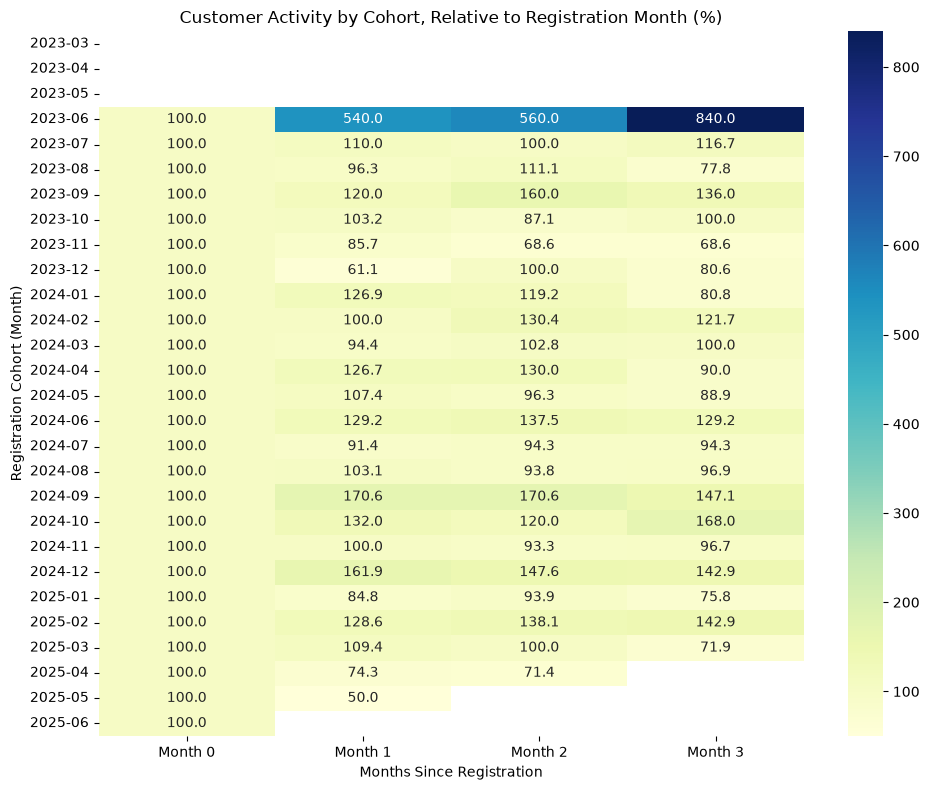

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(cohort_retention, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Customer Activity by Cohort, Relative to Registration Month (%)')
plt.xlabel('Months Since Registration')
plt.ylabel('Registration Cohort (Month)')
plt.tight_layout()
plt.show()

### Cohort Analysis

Unlike a typical retention curve that declines over time, this data shows the opposite pattern: activity in Month 1–3 is often **higher** than Month 0 (the registration month itself) — averaging around 125-140% of Month 0 activity across cohorts.

**Interpretation:** New customers appear to place fewer orders in the exact month they register, then become more active in the following 1-3 months. This suggests registration doesn't immediately translate into purchases — there may be an onboarding lag before customers start actively ordering, which is worth investigating further (e.g. via welcome offers or first-purchase incentives to shorten that lag).

**Caveat:** The most recent cohorts (e.g. 2025-05, 2025-06) show fewer data points since there hasn't been enough time yet to observe their Month 2/3 activity — these should be read with the understanding that the dataset simply hasn't "caught up" to them yet, not necessarily as low retention.